# Лабораторная работа №2. Кластеризация

**Вариант 3**

Цель — выделить группы похожих объектов, обосновать число кластеров и обучить модель кластеризации из scikit-learn. На первых двух шагах загрузим данные и посмотрим на их расположение.

## 1. Загрузка и проверка данных

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

relative_path = Path("tasks/lab2/dataset/lab2-03.xlsx")
data_path = next(
    (folder / relative_path for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / relative_path).is_file()),
    None,
)
if data_path is None:
    raise FileNotFoundError("Запустите ноутбук из папки репозитория calc_methods.")

data = pd.read_excel(data_path, sheet_name="Sheet1", header=0)
data.columns = ["feature_1", "feature_2"]

print(f"Файл: {data_path.name}")
print(f"Объектов: {len(data)}, признаков: {data.shape[1]}")
data.head()

Файл: lab2-03.xlsx
Объектов: 1000, признаков: 2


,feature_1,feature_2
0,-4.526108,-3.231157
1,-2.346786,-4.658288
2,-1.722481,-2.705625
3,10.310193,-3.924825
4,-9.949807,-4.761994


## 2. Визуализация исходных данных


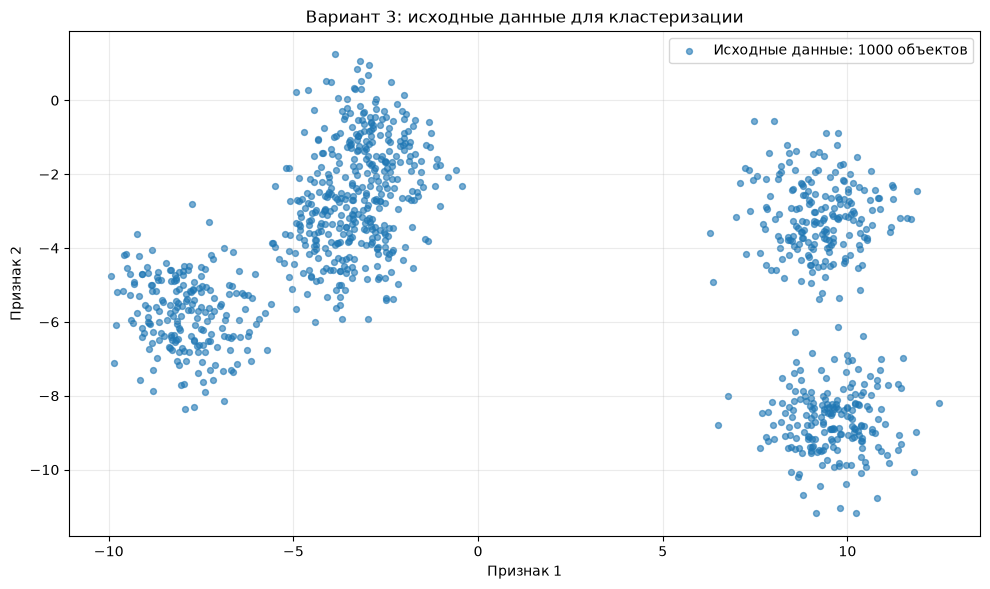

In [2]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(data["feature_1"], data["feature_2"], s=18, alpha=0.6,
           label=f"Исходные данные: {len(data)} объектов")
ax.set_title("Вариант 3: исходные данные для кластеризации")
ax.set_xlabel("Признак 1")
ax.set_ylabel("Признак 2")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Обучающая и тестовая выборки

Случайно выделим 800 объектов для обучения и 200 для последующей проверки.

Фиксируем random_state=42 для воспроизводимости. Тестовые точки не участвуют в подборе центров и числа кластеров.


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(data, test_size=0.2, random_state=42)
print(f"Обучающих объектов: {len(X_train)}")
print(f"Тестовых объектов: {len(X_test)}")

Обучающих объектов: 800
Тестовых объектов: 200


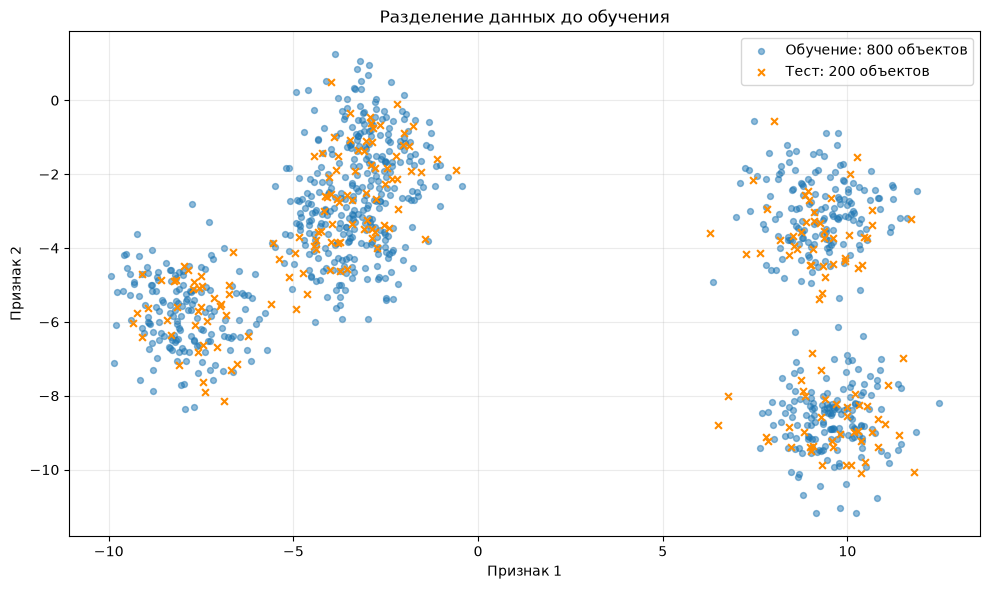

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X_train["feature_1"], X_train["feature_2"], s=18, alpha=0.5,
           label="Обучение: 800 объектов")
ax.scatter(X_test["feature_1"], X_test["feature_2"], s=24, marker="x",
           color="darkorange", label="Тест: 200 объектов")
ax.set_title("Разделение данных до обучения")
ax.set_xlabel("Признак 1")
ax.set_ylabel("Признак 2")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Первая модель KMeans

KMeans — метод k средних: k задаёт число групп, а каждая группа представляется центром (средним её координат). Предварительно возьмём k=4 по четырём крупным областям исходного графика. Это гипотеза, которую далее проверим.

Здесь обучаются координаты четырёх центров: по две координаты у каждого.


Алгоритм уменьшает сумму квадратов расстояний от обучающих точек до центров их групп (inertia). Результат зависит от начальных центров и не гарантирует глобального минимума. `n_init=20` означает 20 запусков с разными начальными центрами; сохраняется лучший по inertia. `random_state=42` делает процедуру воспроизводимой. KMeans сам не выбирает число групп: его мы передаём через `n_clusters`.

In [5]:
from sklearn.cluster import KMeans

initial_k = 4
kmeans_initial = KMeans(
    n_clusters=initial_k,
    init="k-means++",
    n_init=20,
    random_state=42,
)
kmeans_initial.fit(X_train)

train_labels = kmeans_initial.labels_
centers = pd.DataFrame(
    kmeans_initial.cluster_centers_,
    columns=X_train.columns,
)
centers.index.name = "Кластер"
centers["Объектов в обучении"] = np.bincount(train_labels, minlength=initial_k)

print(f"Итераций в выбранном запуске: {kmeans_initial.n_iter_}")
print(f"Сумма квадратов расстояний (inertia): {kmeans_initial.inertia_:.2f}")
print(f"Средний квадрат расстояния до центра: {kmeans_initial.inertia_ / len(X_train):.2f}")
centers.round(3)

Итераций в выбранном запуске: 3
Сумма квадратов расстояний (inertia): 1924.86
Средний квадрат расстояния до центра: 2.41


,feature_1,feature_2,Объектов в обучении
Кластер,,,
0,9.585,-8.650,158
1,-3.267,-2.525,322
2,9.253,-3.039,157
3,-7.916,-5.779,163


### Найденные группы и центры


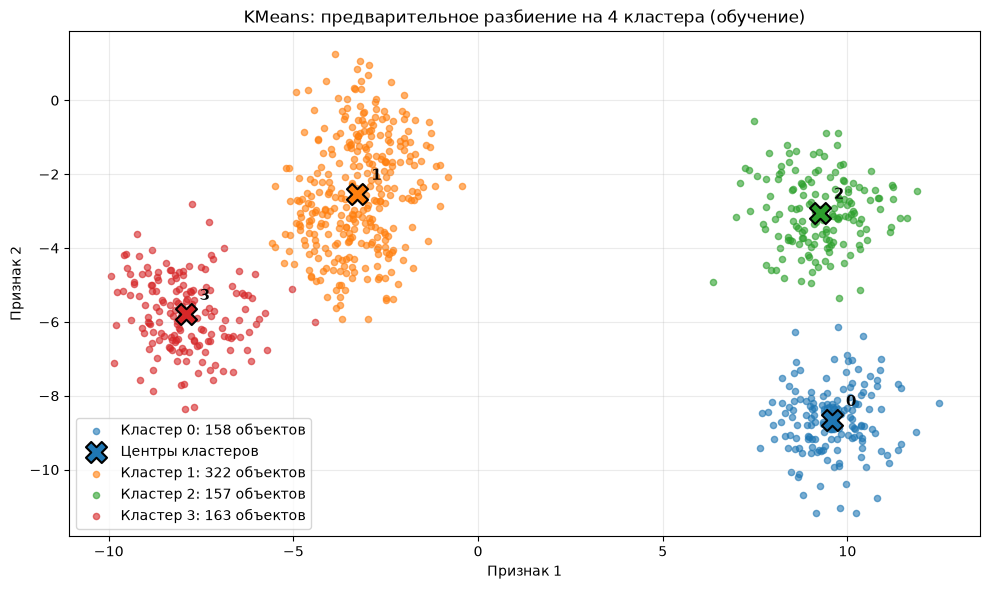

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.get_cmap("tab10").colors
for cluster_id in range(initial_k):
    points = X_train.loc[train_labels == cluster_id]
    center = kmeans_initial.cluster_centers_[cluster_id]
    ax.scatter(points["feature_1"], points["feature_2"], s=20, alpha=0.6,
               color=colors[cluster_id], label=f"Кластер {cluster_id}: {len(points)} объектов")
    ax.scatter(center[0], center[1], marker="X", s=230,
               color=colors[cluster_id], edgecolors="black", linewidths=1.5,
               zorder=4, label="Центры кластеров" if cluster_id == 0 else None)
    ax.annotate(str(cluster_id), center, xytext=(10, 10), textcoords="offset points",
                fontsize=11, fontweight="bold")
ax.set_title("KMeans: предварительное разбиение на 4 кластера (обучение)")
ax.set_xlabel("Признак 1")
ax.set_ylabel("Признак 2")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Сравнение четырёх и пяти групп

Цель — описать отдельные скопления. Сравним k=4 и k=5 по графику и компактности на обучающих данных. Для контекста построим график «локтя» при k=2…10.

Inertia уменьшается при добавлении центров, поэтому её минимум не определяет число групп. Ищем замедление улучшения. Силуэт оставим дополнительной характеристикой отделённости, без автоматического выбора по максимуму. Масштаб признаков сохраняем исходным.

In [7]:
from sklearn.metrics import silhouette_score

candidate_models = {}
selection_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    labels = model.fit_predict(X_train)
    candidate_models[k] = model
    selection_rows.append({
        "k": k,
        "Inertia": model.inertia_,
        "Средний квадрат расстояния": model.inertia_ / len(X_train),
        "Силуэт": silhouette_score(X_train, labels),
    })
selection_results = pd.DataFrame(selection_rows).set_index("k")
selection_results.round(4)

,Inertia,Средний квадрат расстояния,Силуэт
k,,,
2,7898.9158,9.8736,0.7436
3,4413.1857,5.5165,0.6650
4,1924.8628,2.4061,0.6586
5,1359.1573,1.6989,0.5859
6,1238.6024,1.5483,0.5284
7,1129.9423,1.4124,0.4828
8,1010.3160,1.2629,0.4969
9,910.0344,1.1375,0.4184
10,824.6684,1.0308,0.3484


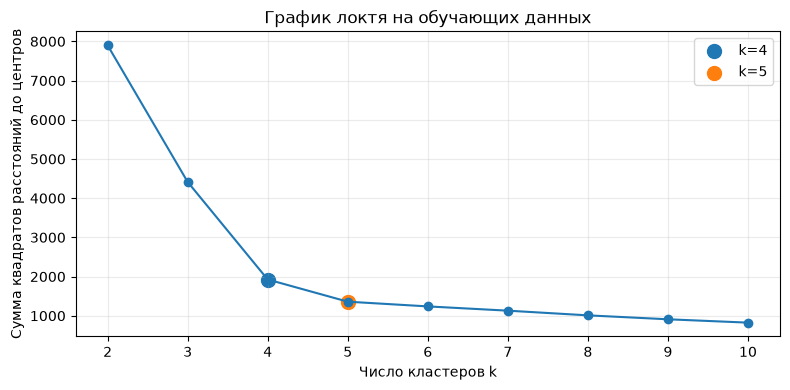

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(selection_results.index, selection_results["Inertia"], "o-")
for k in [4, 5]:
    ax.scatter(k, selection_results.loc[k, "Inertia"], s=100, label=f"k={k}")
ax.set_title("График локтя на обучающих данных")
ax.set_xlabel("Число кластеров k")
ax.set_ylabel("Сумма квадратов расстояний до центров")
ax.set_xticks(selection_results.index)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

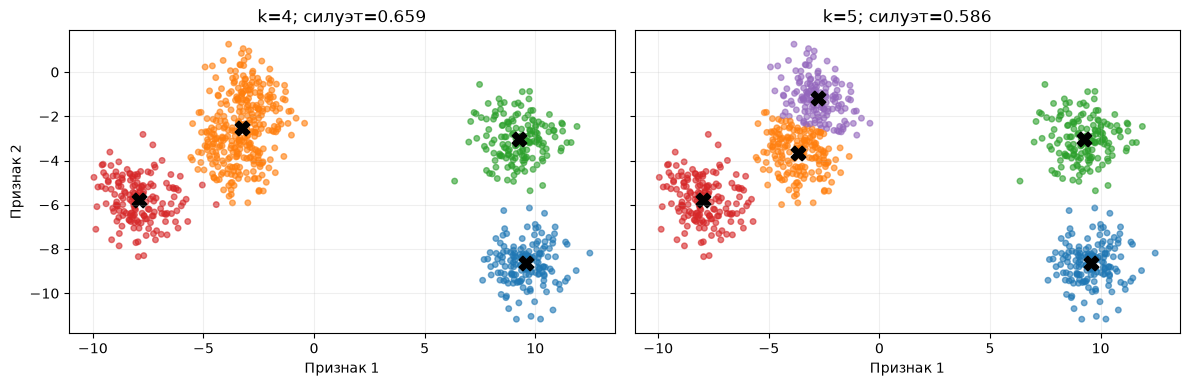

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, k in zip(axes, [4, 5]):
    model = candidate_models[k]
    ax.scatter(X_train["feature_1"], X_train["feature_2"],
               c=model.labels_, cmap="tab10", vmin=0, vmax=9, s=16, alpha=0.6)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
               marker="X", s=110, color="black")
    ax.set_title(f"k={k}; силуэт={selection_results.loc[k, 'Силуэт']:.3f}")
    ax.set_xlabel("Признак 1")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Признак 2")
plt.tight_layout()
plt.show()

### Выбор для подробного описания скоплений

При k=4 вытянутая область слева ближе к центру объединена. При k=5 она разделяется на верхнюю и нижнюю группы, а остальные три скопления сохраняются.

Переход от 4 к 5 уменьшает inertia примерно на 29%, следующий переход от 5 к 6 — только на 9%. Вместе с графиком это даёт основание использовать **k=5 для более подробного описания**. Это обоснованный исследовательский выбор, а не доказательство пяти истинных классов: соседние группы перекрываются, и k=4 остаётся допустимым более крупным разбиением.

Максимум силуэта при k=2 отражает большой промежуток между левой и правой областями. Здесь интересуют скопления внутри этих областей, поэтому максимум силуэта не принимаем за обязательное правило.

In [10]:
chosen_k = 5
kmeans_selected = candidate_models[chosen_k]
print(f"Для дальнейшего анализа выбрано k={chosen_k}")

Для дальнейшего анализа выбрано k=5


## 6. Проверка на отложенных объектах

Назначим 200 тестовым точкам ближайшие центры выбранной модели без повторного обучения. Сравним силуэт и средний квадрат расстояния до своего центра; процент правильных ответов неизвестен, поскольку истинных меток нет.

Число групп выбрано по обучающей части. Однако тест уже использовался ранее при исследовании модели с двумя группами, поэтому текущая проверка — исследовательская оценка на отложенной части, а не полностью новый независимый финальный эксперимент. По её результатам k не корректируем.

In [11]:
selected_train_labels = kmeans_selected.labels_
selected_test_labels = kmeans_selected.predict(X_test)

def clustering_metrics(points, labels):
    assigned_centers = kmeans_selected.cluster_centers_[labels]
    squared_distances = ((points.to_numpy() - assigned_centers) ** 2).sum(axis=1)
    group_count = len(np.unique(labels))
    silhouette = (silhouette_score(points, labels)
                  if 1 < group_count < len(points) else np.nan)
    return {
        "Объектов": len(points),
        "Представлено кластеров": group_count,
        "Средний квадрат расстояния": squared_distances.mean(),
        "Силуэт": silhouette,
    }

quality_results = pd.DataFrame({
    "Обучение": clustering_metrics(X_train, selected_train_labels),
    "Тест": clustering_metrics(X_test, selected_test_labels),
}).T
quality_results.round(4)

,Объектов,Представлено кластеров,Средний квадрат расстояния,Силуэт
Обучение,800.0,5.0,1.6989,0.5859
Тест,200.0,5.0,1.7565,0.5731


In [12]:
cluster_summary = pd.DataFrame(kmeans_selected.cluster_centers_, columns=data.columns)
cluster_summary.index.name = "Кластер"
cluster_summary["Объектов в обучении"] = np.bincount(selected_train_labels, minlength=chosen_k)
cluster_summary["Объектов в тесте"] = np.bincount(selected_test_labels, minlength=chosen_k)
cluster_summary.round(3)

,feature_1,feature_2,Объектов в обучении,Объектов в тесте
Кластер,,,,
0,9.585,-8.650,158,42
1,-3.678,-3.681,177,40
2,9.253,-3.039,157,43
3,-7.956,-5.782,161,40
4,-2.791,-1.174,147,35


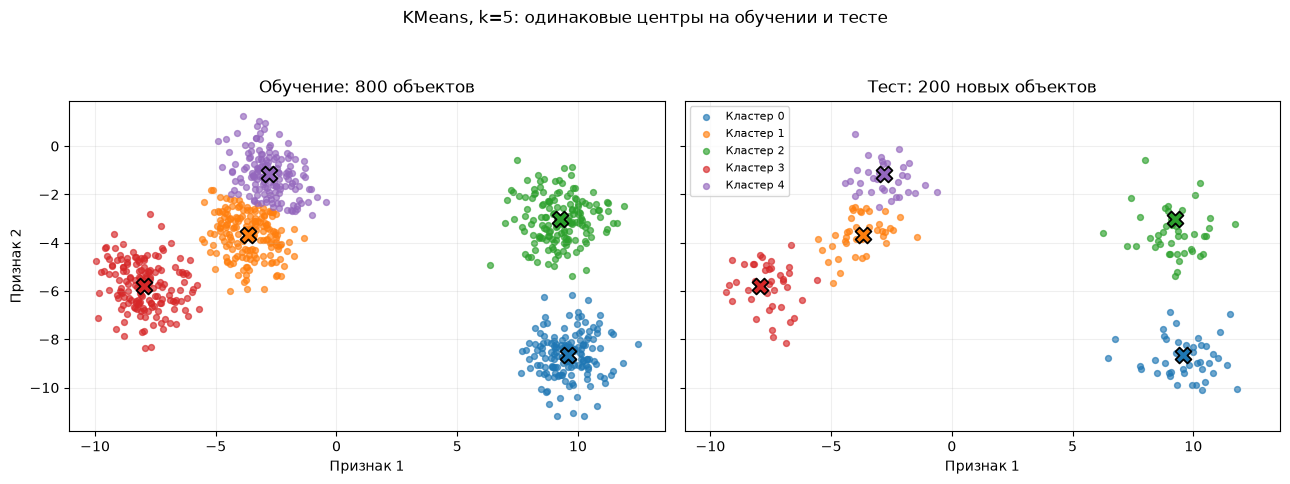

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, points, labels, title in [
    (axes[0], X_train, selected_train_labels, "Обучение: 800 объектов"),
    (axes[1], X_test, selected_test_labels, "Тест: 200 новых объектов"),
]:
    for cluster_id in range(chosen_k):
        group = points.loc[labels == cluster_id]
        center = kmeans_selected.cluster_centers_[cluster_id]
        ax.scatter(group["feature_1"], group["feature_2"], s=18, alpha=0.65,
                   color=colors[cluster_id], label=f"Кластер {cluster_id}")
        ax.scatter(*center, marker="X", s=130, color=colors[cluster_id],
                   edgecolors="black", linewidths=1.3, zorder=4)
    ax.set_title(title)
    ax.set_xlabel("Признак 1")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Признак 2")
axes[1].legend(fontsize=8)
fig.suptitle(f"KMeans, k={chosen_k}: одинаковые центры на обучении и тесте")
plt.tight_layout()
plt.show()

## 7. Вывод

KMeans применён к двум числовым признакам в исходном масштабе. Сравнение 4 и 5 групп показало, что пять групп дают более подробное описание вытянутого скопления; уменьшение inertia после пяти замедляется. Разбиение на две области лучше по силуэту, но описывает более крупный уровень структуры.

Принято k=5 как рабочее разбиение для описания отдельных скоплений. Центры найдены по 800 обучающим объектам, остальные 200 распределены по ближайшим центрам. Метрики приведены выше. Предметный смысл признаков и истинные метки неизвестны, поэтому нельзя утверждать, что число групп установлено однозначно.

На тесте средний квадрат расстояния до центра равен 1,7565 (на обучении — 1,6989), силуэт — 0,5731 (на обучении — 0,5859). Показатели близки, все пять групп представлены в тестовой выборке. Это поддерживает применимость разбиения к отложенным объектам, но не доказывает истинность пяти классов.